# 03 · Ink detection: a small 2.5D CNN

**Goal.** Train a model that looks at a stack of surface layers and predicts ink, and measure how far a tiny model gets.

**Data.**

| object | shape | role |
|---|---|---|
| surface volume of segment w025, level 1 | 28 × 3,640 × 3,400 (18.7 µm pixels) | input |
| official ink prediction (2.4 µm model), resized to the same canvas | 3,640 × 3,400, 0..1 | **pseudo-label** |

**Honest framing.** These labels are another model's output, not human ink labels. Training on them is
*distillation*: our small model learns to imitate a big one from a coarser scan. What it can show is whether the
9 µm data carries the signal the 2.4 µm model found, on regions it never trained on.

**The split is spatial.** Neighbouring patches share pixels, so a random patch split leaks. We train on the left
60% of the sheet and validate on the right 40%.

In [ ]:
# On Google Colab: fetch the code and the two missing libraries. Locally this cell does nothing.
import sys, os
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/vesuvius-labs'):
        !git clone -q https://github.com/alexchilton/vesuvius-labs /content/vesuvius-labs
        !pip -q install "zarr<3" s3fs tifffile
    os.chdir('/content/vesuvius-labs/notebooks')

In [1]:
import sys, time, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')
import vlab
plt.rcParams.update({'figure.dpi': 110, 'image.cmap': 'gray'})

surface volume (28, 3640, 3400), 347 MB, 40s


label (3640, 3400) mean 0.282 | valid pixels 81.5%


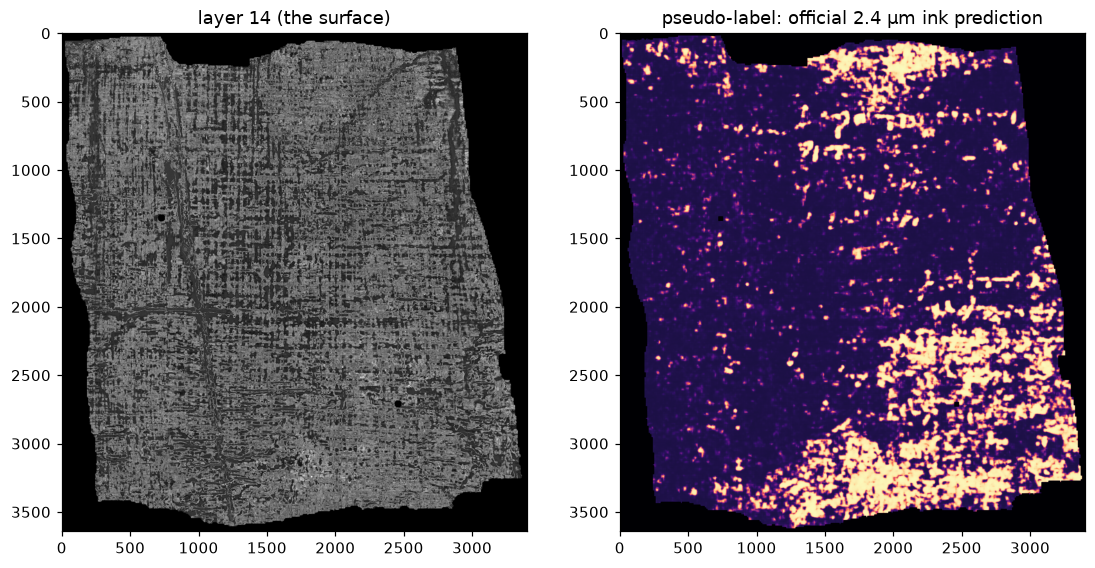

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F, tifffile
from PIL import Image
S1 = vlab.segment_surface(1)
t = time.time(); X = vlab.crop(S1, 'seg_l1', slice(None), slice(None), slice(None)); print(f'surface volume {X.shape}, {X.nbytes / 1e6:.0f} MB, {time.time() - t:.0f}s')
ink = tifffile.imread(vlab.fetch_ink())
Yl = np.asarray(Image.fromarray(ink).resize((X.shape[2], X.shape[1]), Image.BILINEAR), np.float32) / 255.
valid = X.max(0) > 0
print('label', Yl.shape, f'mean {Yl[valid].mean():.3f}', '| valid pixels', f'{valid.mean():.1%}')
fig, ax = plt.subplots(1, 2, figsize=(12, 6)); ax[0].imshow(X[14]); ax[0].set_title('layer 14 (the surface)')
ax[1].imshow(Yl, cmap='magma'); ax[1].set_title('pseudo-label: official 2.4 µm ink prediction'); plt.show()

Layer 14 alone shows no letters: this is the point of the challenge. The label shows a line of Greek letters near the
top and a lot of speckle lower down. The speckle is uncertainty in the big model, and our model will learn it too.

## 1. Patches and the split

In [3]:
dev = 'mps' if torch.backends.mps.is_available() else 'cpu'
L0, L1 = 6, 22                                     # 16 layers around the surface
Xn = (X[L0:L1].astype(np.float32) / 255. - 0.5) / 0.25
P, H, W = 64, *X.shape[1:]
cut = int(W * 0.6)
def sample(n, train, rng):
    xs, ys = [], []
    while len(xs) < n:
        i = rng.integers(0, H - P); j = rng.integers(0, cut - P) if train else rng.integers(cut, W - P)
        if valid[i:i + P, j:j + P].mean() < 0.9: continue
        xs.append(Xn[:, i:i + P, j:j + P]); ys.append(Yl[i:i + P, j:j + P])
    return torch.tensor(np.stack(xs)), torch.tensor(np.stack(ys))[:, None]
rng = np.random.default_rng(0); xv, yv = sample(512, False, rng)
print('device', dev, '| input layers', L1 - L0, '| patch', P, '| train columns <', cut, '| val patches', len(xv))

device mps | input layers 16 | patch 64 | train columns < 2040 | val patches 512


## 2. The model

A small 2.5D net: 3D convolutions read the layer stack, a max over depth collapses it to 2D
(the challenge's own `z_projection_mode: max`), and a few 2D convolutions produce the ink map.

In [4]:
class Ink25D(nn.Module):
    def __init__(s, c=16):
        super().__init__()
        s.enc = nn.Sequential(nn.Conv3d(1, c, 3, padding=1), nn.GELU(), nn.Conv3d(c, c, 3, padding=1), nn.GELU(),
                              nn.Conv3d(c, 2 * c, (3, 3, 3), padding=1), nn.GELU())
        s.dec = nn.Sequential(nn.Conv2d(2 * c, 2 * c, 3, padding=1), nn.GELU(), nn.Conv2d(2 * c, 2 * c, 3, padding=2, dilation=2),
                              nn.GELU(), nn.Conv2d(2 * c, 1, 1))
    def forward(s, x):                             # x: (B, layers, H, W)
        return s.dec(s.enc(x[:, None]).amax(2))    # max over depth -> (B, 2c, H, W) -> logits
net = Ink25D().to(dev); print(sum(p.numel() for p in net.parameters()), 'parameters')

39761 parameters


In [5]:
opt = torch.optim.AdamW(net.parameters(), 2e-3, weight_decay=1e-4)
def val_corr():
    net.eval(); out = []
    with torch.no_grad():
        for k in range(0, len(xv), 64): out.append(torch.sigmoid(net(xv[k:k + 64].to(dev))).cpu())
    p = torch.cat(out).ravel().numpy(); return np.corrcoef(p, yv.ravel().numpy())[0, 1]
t = time.time(); hist = []
for step in range(1, 1501):
    net.train(); xb, yb = sample(16, True, rng)
    loss = F.binary_cross_entropy_with_logits(net(xb.to(dev)), yb.to(dev))
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 250 == 0:
        hist.append((step, loss.item(), val_corr())); print(f'step {step} loss {loss.item():.4f} val corr {hist[-1][2]:.3f} ({time.time() - t:.0f}s)')

step 250 loss 0.5720 val corr 0.153 (93s)


step 500 loss 0.5199 val corr 0.223 (191s)


step 750 loss 0.6504 val corr 0.246 (296s)


step 1000 loss 0.4833 val corr 0.264 (394s)


step 1250 loss 0.5133 val corr 0.305 (489s)


step 1500 loss 0.5294 val corr 0.315 (581s)


## 3. Baseline: is it just brightness?

If ink were simply denser papyrus, one layer's brightness would predict the label. Compare.

In [6]:
base = np.corrcoef(xv[:, 14 - L0 - 2:14 - L0 + 3].mean(1).ravel().numpy(), yv.ravel().numpy())[0, 1]
print(f'held-out correlation with the pseudo-label: brightness of the surface layers {base:.3f}  vs  2.5D CNN {hist[-1][2]:.3f}')

held-out correlation with the pseudo-label: brightness of the surface layers 0.110  vs  2.5D CNN 0.315


## 4. Predict the whole sheet

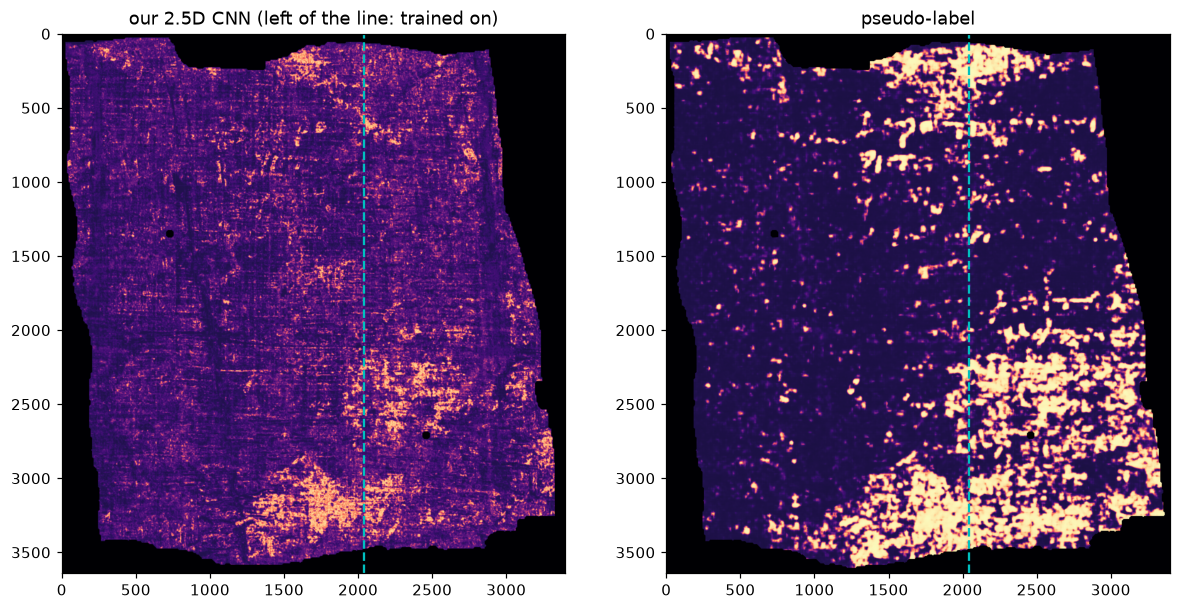

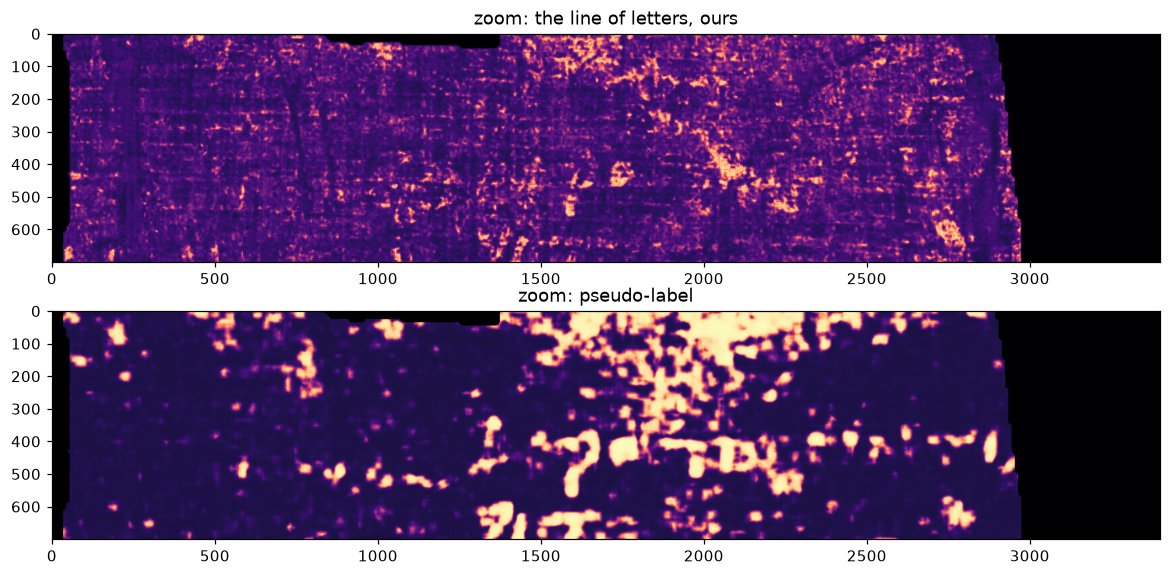

In [7]:
net.eval(); pred = np.zeros((H, W), np.float32); cnt = np.zeros((H, W), np.float32); T = 256
with torch.no_grad():
    for i in range(0, H - T + 1, T // 2):
        for j in range(0, W - T + 1, T // 2):
            if valid[i:i + T, j:j + T].mean() < 0.2: continue
            p = torch.sigmoid(net(torch.tensor(Xn[None, :, i:i + T, j:j + T]).to(dev)))[0, 0].cpu().numpy()
            pred[i:i + T, j:j + T] += p; cnt[i:i + T, j:j + T] += 1
pred = np.where(cnt > 0, pred / np.maximum(cnt, 1), 0) * valid
fig, ax = plt.subplots(1, 2, figsize=(13, 6.5))
ax[0].imshow(pred, cmap='magma'); ax[0].axvline(cut, c='c', ls='--'); ax[0].set_title('our 2.5D CNN (left of the line: trained on)')
ax[1].imshow(Yl * valid, cmap='magma'); ax[1].axvline(cut, c='c', ls='--'); ax[1].set_title('pseudo-label'); plt.show()
top = slice(200, 900)
fig, ax = plt.subplots(2, 1, figsize=(13, 6)); ax[0].imshow(pred[top], cmap='magma'); ax[0].set_title('zoom: the line of letters, ours')
ax[1].imshow((Yl * valid)[top], cmap='magma'); ax[1].set_title('zoom: pseudo-label'); plt.show()

## What to take away

- The letters are invisible in any single layer. Brightness alone correlates 0.11 with the label on the held-out strip;
  the CNN reaches about 0.31 after 1,500 steps and is still rising. The signal is texture across depth, not brightness.
- 0.31 is not readable letters: the prediction picks up ink-like texture and the big model's speckle, but the strokes
  are blurred. Closing that gap with few labels is what notebook 04 tests.
- Everything right of the dashed line was never trained on. That is the only part of the picture that counts.
- This model imitates another model. Its letters are only as real as the big model's; the challenge's prizes demand
  held-out validation and papyrologist review for exactly this reason.

## Check yourself

1. Why would a random train/validation patch split overstate the score here?
2. What does `amax` over depth assume about where the ink sits in the stack?
3. The pseudo-label is speckled in the lower half. How would you stop the model learning the speckle?
4. A model trained on one fragment is tested on another. What do you expect to happen to the correlation, and why?